### ELO328 - Procesamiento Digital de Imágenes
# Clase 19: Reconocimiento de formas
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Transformada de Hough

Técnica para la detección de cualquier forma (que se pueda representar matemáticamente) en imágenes digitales. Es capaz de detectar la forma incluso si está rota o distorsionada un poco. Veremos cómo funciona para una línea.

Una recta se puede representar como $y = m*x + n$ o en forma paramétrica, como ${\displaystyle \rho =x*\cos {\theta }+y*\sin {\theta }}$ donde $\rho$ es la distancia perpendicular desde el origen a la recta, y $\theta$ es el ángulo formado por esta recta perpendicular y el eje horizontal. Entonces, es posible asociar a cada recta un par $(\rho,\theta)$ que es único y el espacio se denomina espacio de Hough para el conjunto de rectas en dos dimensiones.

<div align="center">
    <img src="img/houghlines1.svg" alt="" width="20%" align="center" />
</div>

## Algoritmo

El algoritmo de la transformada de Hough usa una matriz, llamada acumulador, cuya dimensión es igual al número de parámetros desconocidos del problema. Aquí se muestra un pseudocódigo de como debería funcionar el algoritmo para detectar rectas en una imagen:

<pre>
1:    cargar imagen
2:    detectar los bordes en la imagen
3:    por cada punto en la imagen:
4:       si el punto (𝒙,𝒚) esta en un borde:
5:          por todos los posibles ángulos 𝜽:
6:             calcular 𝝆 para el punto (𝒙,𝒚) con un ángulo 𝜽 
7:             incrementar la posición (𝝆,𝜽) en el acumulador
8:    buscar las posiciones con los mayores valores en el acumulador
9:    devolver las rectas cuyos valores son los mayores en el acumulador.
</pre>

### Ejemplo
Considera tres puntos, mostrados aquí como puntos negros:

<div align="right">
    <img src="img/Hough_transform_diagram.png" alt="" width="40%" align="right" />
</div>

Por cada punto se dibujan un número de líneas que pasan por los mismos, con distintos ángulos. Son las líneas continuas.

Por cada línea se dibuja una recta perpendicular a esta que pasa por el origen de coordenadas. Son las líneas discontinuas.

La longitud y el ángulo de cada línea discontinua se calcula. Los resultados se muestran en las tablas.

Esto se repite por cada punto.

#### Espacio de Hough

Se crea un gráfico con las longitudes de las líneas por cada ángulo, conocido como el espacio de Hough.

<div align="center">
    <img src="img/Hough_space_plot_example.png" alt="" width="30%" align="center" />
</div>

El punto donde las curvas se intersecan da la distancia y el ángulo. Esta distancia y este ángulo indican la recta que se interseca con los puntos anteriores. El gráfico muestra el punto donde se intersecan las tres curvas, este punto corresponde a la recta rosada de la figura anterior, que pasa por los tres puntos negros.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

In [ ]:
import warnings
from cryptography.utils import CryptographyDeprecationWarning
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', category=CryptographyDeprecationWarning)
    
from skimage.transform import hough_line, hough_line_peaks
from skimage.feature import canny
from skimage.draw import line as draw_line
from skimage import data
from skimage.io import imread

In [3]:
image = np.zeros((150,150))

image[25, 25] = 255
image[50, 50] = 255
image[75, 75] = 255
image[100, 100] = 255
image[125, 125] = 255

accumulator, thetas, rhos = hough_line(image)

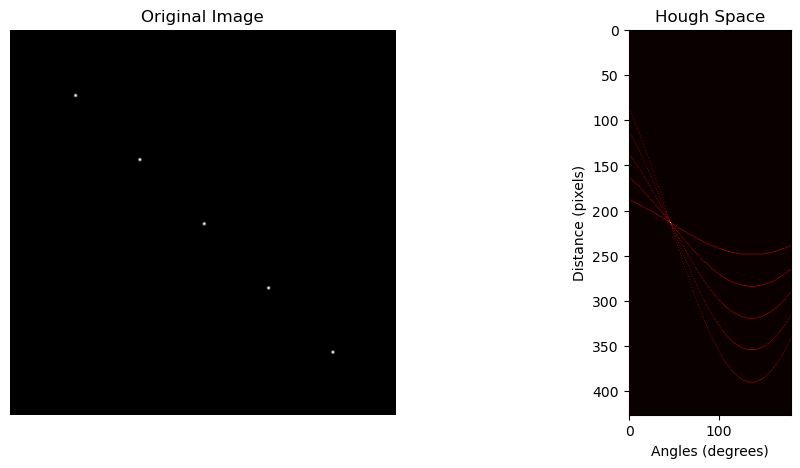

In [4]:
fig, axes = plt.subplots(1,2, figsize=(12, 5))
axes[0].imshow(image, cmap=cm.gray)
axes[0].set_title('Original Image')
axes[0].axis('off')
axes[1].imshow(accumulator, cmap='hot')
axes[1].set_title('Hough Space')
axes[1].set_xlabel('Angles (degrees)')
axes[1].set_ylabel('Distance (pixels)')
plt.show()

# Ejemplo detección líneas

In [5]:
def plot_toy_detection():
    image = np.zeros((200, 200))
    idx = np.arange(25, 175)
    image[idx, idx] = 255
    image[draw_line(45, 25, 25, 175)] = 255
    image[draw_line(25, 135, 175, 155)] = 255

    tested_angles = np.linspace(-np.pi / 2, np.pi / 2, 360, endpoint=False)
    h, theta, d = hough_line(image, theta=tested_angles)

    fig, axes = plt.subplots(1, 3, figsize=(15, 6))
    ax = axes.ravel()

    ax[0].imshow(image, cmap=cm.gray)
    ax[0].set_title('Input image')
    ax[0].set_axis_off()

    angle_step = 0.5 * np.diff(theta).mean()
    d_step = 0.5 * np.diff(d).mean()
    bounds = [np.rad2deg(theta[0] - angle_step),
              np.rad2deg(theta[-1] + angle_step),
              d[-1] + d_step, d[0] - d_step]
    ax[1].imshow(np.log(1 + h), extent=bounds, cmap='hot', aspect=1 / 1.5)
    ax[1].set_title('Hough space')
    ax[1].set_xlabel('Angles (degrees)')
    ax[1].set_ylabel('Distance (pixels)')
    ax[1].axis('image')

    ax[2].imshow(image, cmap=cm.gray)
    ax[2].set_ylim((image.shape[0], 0))
    ax[2].set_axis_off()
    ax[2].set_title('Detected lines')

    for _, angle, dist in zip(*hough_line_peaks(h, theta, d)):
        (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
        ax[2].axline((x0, y0), slope=np.tan(angle + np.pi/2), lw=5, alpha=.5, color='r')

    plt.tight_layout()
    plt.show()

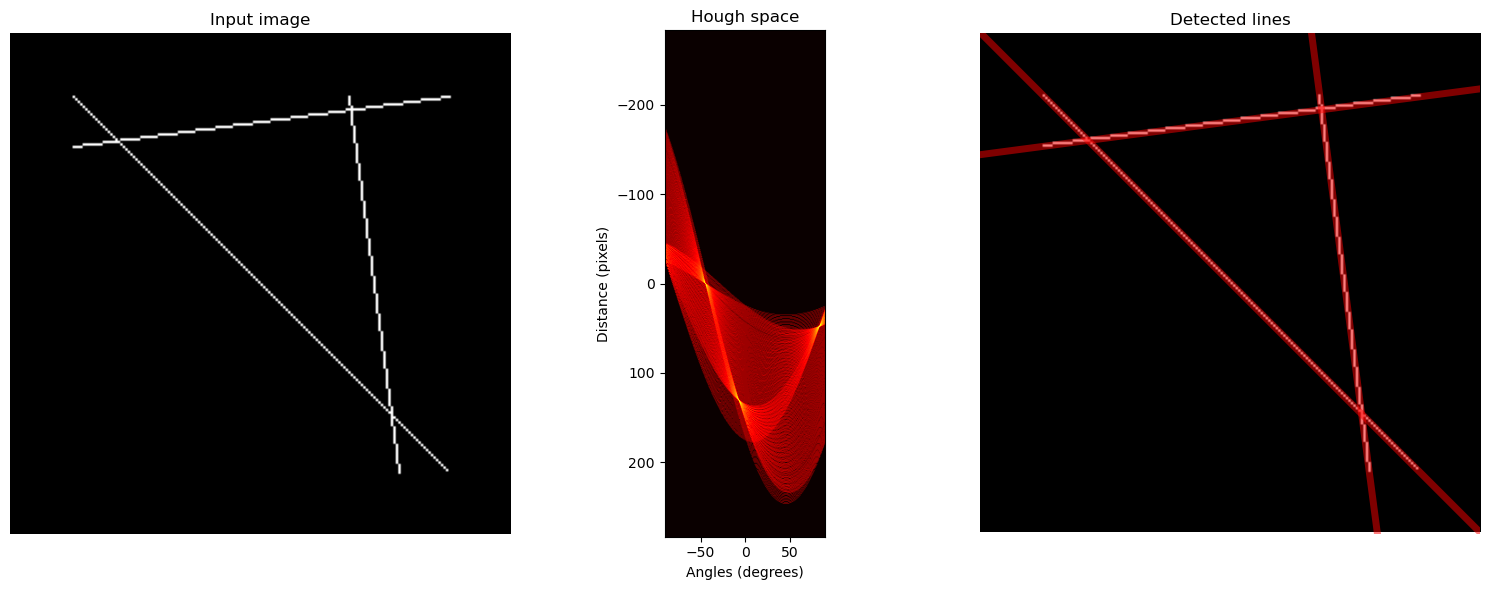

In [6]:
plot_toy_detection()

In [7]:
np.seterr(divide='ignore', invalid='ignore')

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

In [8]:
def plot_image_with_lines_hough(image, lines):
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(image, cmap='gray')
    axes[0].set_title('Original Image')
    axes[0].axis('off')

    axes[1].imshow(image, cmap='gray')
    for _, angle, dist in zip(*lines):
        y0 = (dist - 0 * np.cos(angle)) / np.sin(angle)
        y1 = (dist - image.shape[1] * np.cos(angle)) / np.sin(angle)
        axes[1].plot((0, image.shape[1]), (y0, y1), 'r')
    axes[1].set_xlim((0, image.shape[1]))
    axes[1].set_ylim((image.shape[0], 0))
    axes[1].set_title('Hough Detection Lines')
    axes[1].axis('off')

    plt.show()

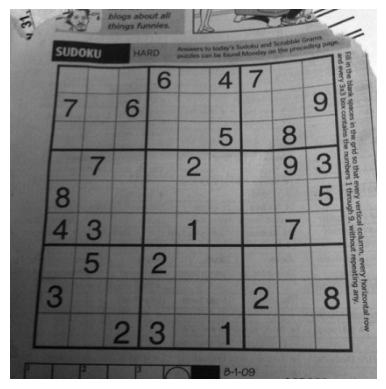

In [9]:
sudoku = imread('img/sudoku.jpg', as_gray=True)
plt.imshow(sudoku, cmap='gray')
plt.axis('off')
plt.show()

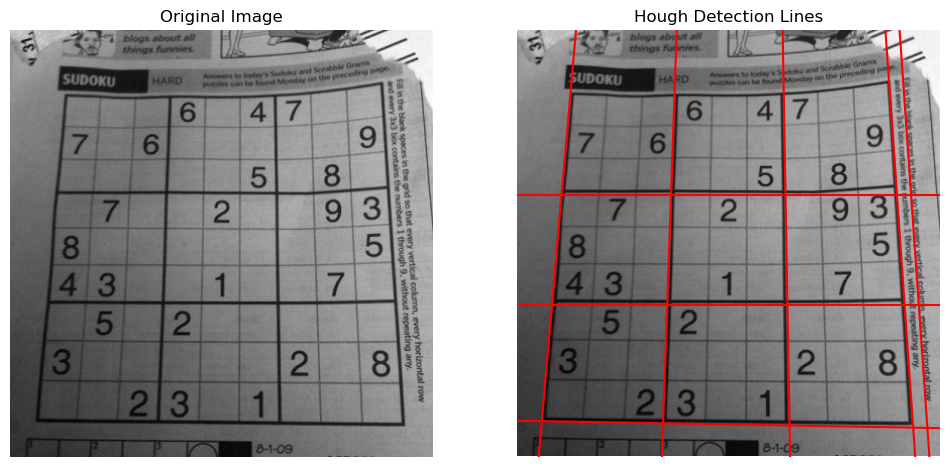

In [10]:
edges = canny(sudoku, sigma=2, low_threshold=0.1, high_threshold=0.3)
h, theta, d = hough_line(edges)
lines = hough_line_peaks(h, theta, d)
plot_image_with_lines_hough(sudoku, lines)

# Transformada Probabilística de Hough 

En la Transformada de Hough, se necesitan muchos cálculos. La transformada probabilística de Hough es una optimización que no toma en consideración todos los puntos, sino que toma solo un subconjunto aleatorio de puntos y eso es suficiente para la detección de líneas. Sólo tenemos que disminuir el umbral.

In [11]:
from skimage.transform import probabilistic_hough_line

In [12]:
def plot_image_with_lines_p_hough(image, lines):
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(image, cmap='gray')
    axes[0].set_title('Original Image')
    axes[0].axis('off')

    axes[1].imshow(image, cmap='gray')
    for line in lines:
        p0, p1 = line
        axes[1].plot((p0[0], p1[0]), (p0[1], p1[1]), 'g')
    axes[1].set_title('Probabilistic Hough Detection Lines')
    axes[1].axis('off')

    plt.show()

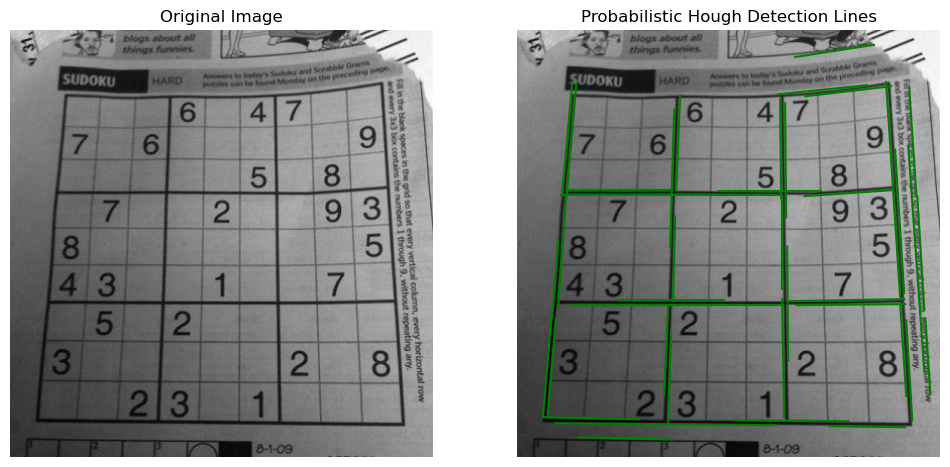

In [13]:
lines = probabilistic_hough_line(edges, threshold=10, line_length=75, line_gap=5)
plot_image_with_lines_p_hough(sudoku, lines)

# Transformaciones circulares de Hough

La Transformada de Hough no se restringe solamente a la detección de rectas, a pesar de que se usa comúnmente con este propósito. Otras figuras geométricas que se pueden describir con unos cuantos parámetros se pueden detectar también con esta técnica.

Por ejemplo, si se quieren detectar circunferencias con la ecuación ${\displaystyle (x-a)^{2}+(y-b)^{2}=r^{2}}$, son necesarios tres parámetros: el centro de la circunferencia $(a,b)$ y el radio ${\displaystyle (r)}$. Por lo tanto, para encontrar circunferencias usando la transformada de Hough, se necesita un acumulador con tres dimensiones ${\displaystyle (a,b,r)}$.

In [14]:
from skimage import data, color
from skimage.util import img_as_ubyte
from skimage.draw import circle_perimeter
from skimage.transform import hough_circle, hough_circle_peaks

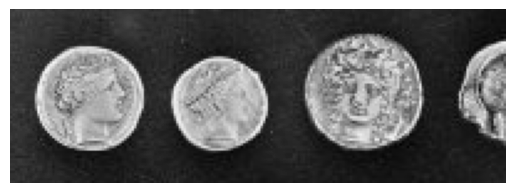

In [15]:
coins = img_as_ubyte(data.coins()[160:230, 70:270])
plt.imshow(coins, cmap='gray')
plt.axis('off')
plt.show()

In [16]:
def plot_circles(image, cx, cy, radii):
    fig, ax = plt.subplots(ncols=1, nrows=1)
    image = color.gray2rgb(image)
    for center_y, center_x, radius in zip(cy, cx, radii):
        circy, circx = circle_perimeter(center_y, center_x, radius,
                                        shape=image.shape)
        image[circy, circx] = (220, 20, 20)

    ax.imshow(image, cmap=plt.cm.gray)
    plt.axis('off')
    plt.show()

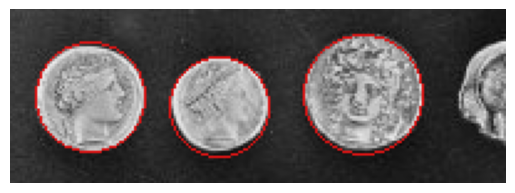

In [17]:
edges = canny(coins, sigma=3, low_threshold=10, high_threshold=50)

hough_radii = np.arange(20, 35, 2)
hough_res = hough_circle(edges, hough_radii)
accums, cx, cy, radii = hough_circle_peaks(hough_res, hough_radii, total_num_peaks=3)

plot_circles(coins, cx, cy, radii)

# Transformada de Fourier

Herramienta matemática que se utiliza para descomponer una señal en sus componentes de frecuencia (espectro). En el caso del procesamiento de imágenes, se puede utilizar para analizar el contenido de frecuencia de una imagen, lo que puede resultar útil para tareas como el filtrado de imágenes y la extracción de características.

<div align="center">
    <img src="img/transformada-de-fourier-detalle.png" alt="" width="70%" align="center" />
</div>

In [18]:
from skimage.color import rgb2gray

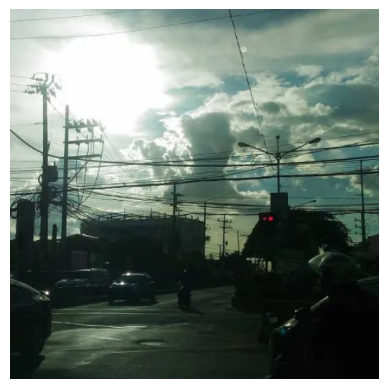

In [19]:
dark_image = imread('img/against_the_light.png')
plt.imshow(dark_image)
plt.axis('off')
plt.show()

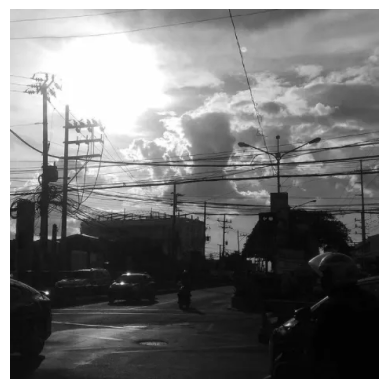

In [20]:
dark_image_grey = rgb2gray(dark_image)
plt.imshow(dark_image_grey, cmap='gray')
plt.axis('off')
plt.show()

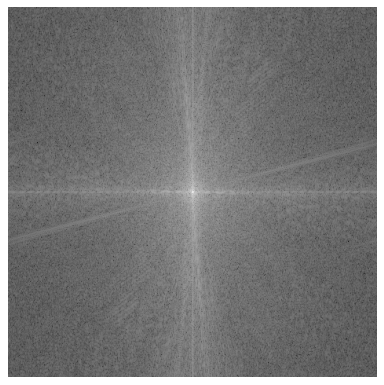

In [21]:
dark_image_grey_fourier = np.fft.fftshift(np.fft.fft2(dark_image_grey))
plt.figure(num=None, figsize=(8, 6), dpi=80)
plt.imshow(np.log(abs(dark_image_grey_fourier)), cmap='gray')
plt.axis('off')
plt.show()

In [22]:
def fourier_masker_ver(image, i):
    f_size = 15
    dark_image_grey_fourier = np.fft.fftshift(np.fft.fft2(rgb2gray(image)))
    dark_image_grey_fourier[:225, 235:240] = i
    dark_image_grey_fourier[-225:,235:240] = i
    fig, ax = plt.subplots(1,3,figsize=(15,15))
    ax[0].imshow(np.log(abs(dark_image_grey_fourier)), cmap='gray')
    ax[0].set_title('Masked Fourier', fontsize = f_size)
    ax[0].axis('off')
    ax[1].imshow(rgb2gray(image), cmap = 'gray')
    ax[1].set_title('Greyscale Image', fontsize = f_size)
    ax[1].axis('off')
    ax[2].imshow(abs(np.fft.ifft2(dark_image_grey_fourier)), 
                     cmap='gray')
    ax[2].set_title('Transformed Greyscale Image', 
                     fontsize = f_size)
    ax[2].axis('off')
    plt.show()

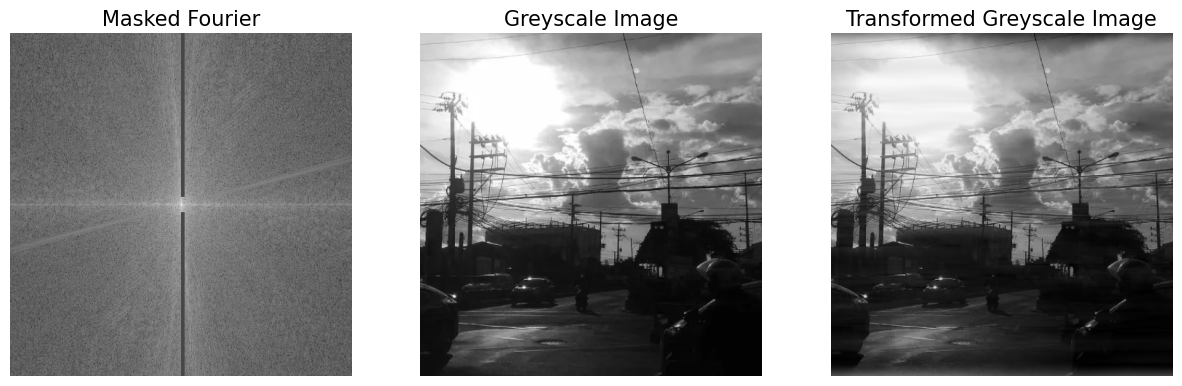

In [23]:
fourier_masker_ver(dark_image, 1)

In [24]:
def fourier_masker_hor(image, i):
    f_size = 15
    dark_image_grey_fourier = np.fft.fftshift(np.fft.fft2(rgb2gray(image)))
    dark_image_grey_fourier[235:240, :230] = i
    dark_image_grey_fourier[235:240,-230:] = i
    fig, ax = plt.subplots(1,3,figsize=(15,15))
    ax[0].imshow(np.log(abs(dark_image_grey_fourier)), cmap='gray')
    ax[0].set_title('Masked Fourier', fontsize = f_size)
    ax[0].axis('off')
    ax[1].imshow(rgb2gray(image), cmap = 'gray')
    ax[1].set_title('Greyscale Image', fontsize = f_size)
    ax[1].axis('off')
    ax[2].imshow(abs(np.fft.ifft2(dark_image_grey_fourier)), 
                     cmap='gray')
    ax[2].set_title('Transformed Greyscale Image', 
                     fontsize = f_size)
    ax[2].axis('off')
    plt.show()

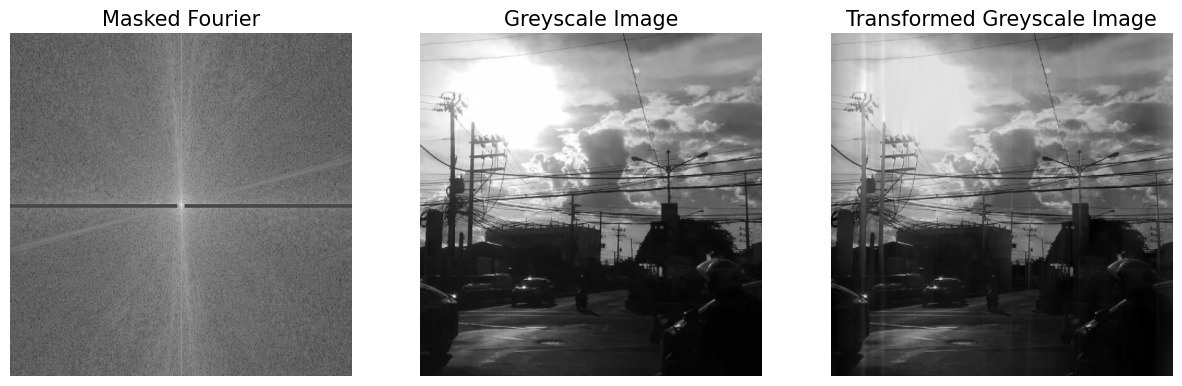

In [25]:
fourier_masker_hor(dark_image, 1)

In [26]:
def fourier_iterator(image, value_list):
    for i in value_list:
        fourier_masker_ver(image, i)

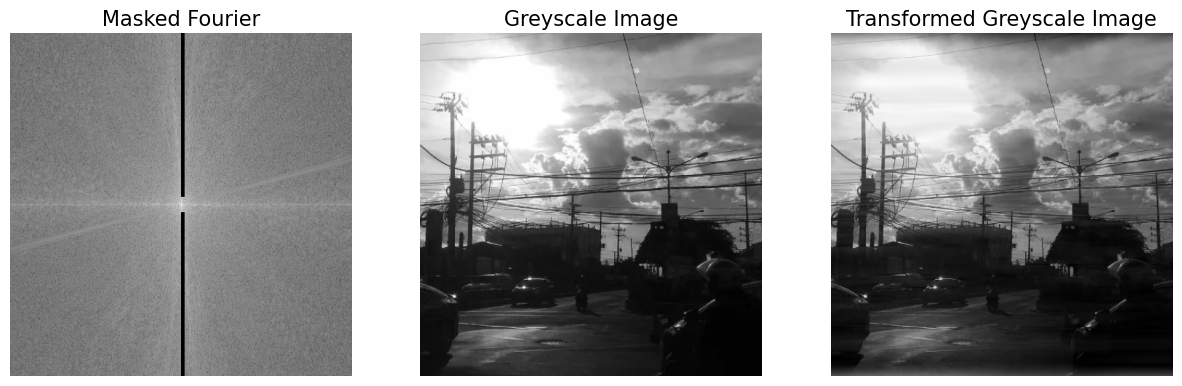

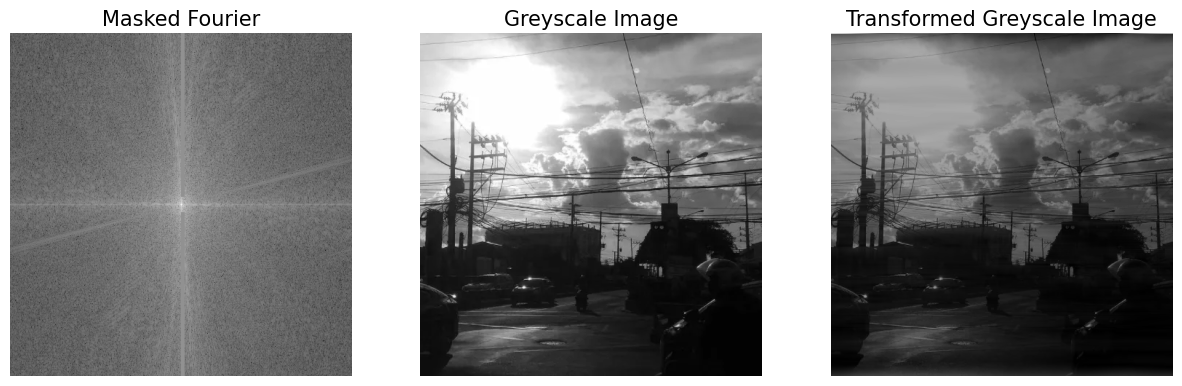

In [27]:
fourier_iterator(dark_image, [0.001, 100])

In [28]:
def fourier_transform_rgb(image):
    f_size = 25
    transformed_channels = []
    
    for i in range(3):
        rgb_fft = np.fft.fftshift(np.fft.fft2(image[:, :, i]))
        rgb_fft[:225, 235:237] = 1
        rgb_fft[-225:, 235:237] = 1
        transformed_channel = np.abs(np.fft.ifft2(rgb_fft))
        
        # Normalize the transformed channel to 0-255 range
        normalized_channel = (transformed_channel - np.min(transformed_channel)) / (np.max(transformed_channel) 
                            - np.min(transformed_channel)) * 255
        transformed_channels.append(normalized_channel.astype(int))
    
    final_image = np.dstack(transformed_channels)
    
    fig, ax = plt.subplots(1, 2, figsize=(15,15))    
    ax[0].imshow(image)
    
    ax[0].set_title('Original Image', fontsize = f_size)
    ax[0].set_axis_off()
    ax[0].axis('off')
    ax[1].imshow(final_image.astype(np.uint8))
    ax[1].set_title('Transformed Image', fontsize = f_size)
    ax[1].set_axis_off()
    ax[1].axis('off')
    fig.tight_layout()
    plt.show()

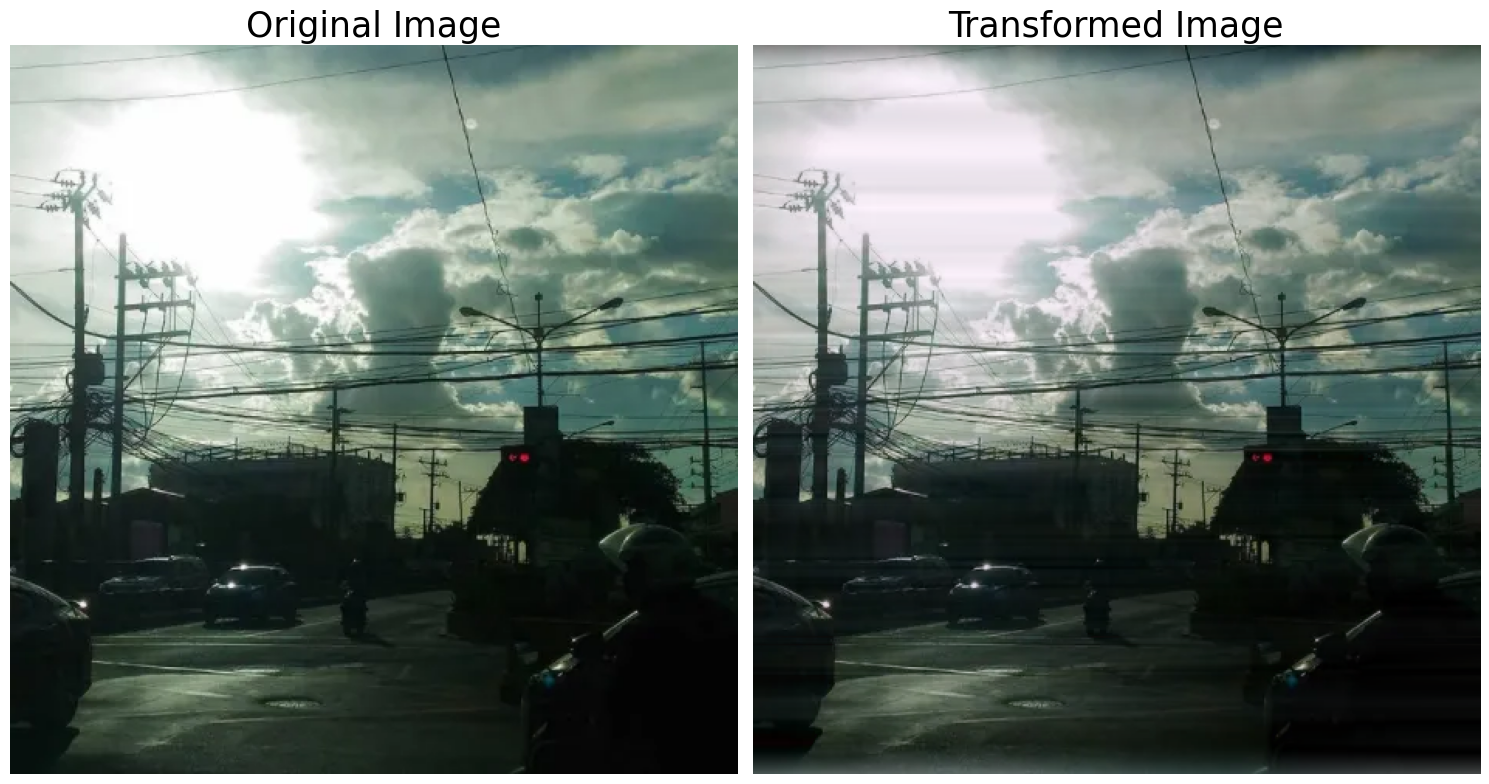

In [29]:
fourier_transform_rgb(dark_image)